# Integración del notebook 05 con el notebook 06

Este notebook toma la exploración y preparación del notebook 05 y agrega el flujo completo de modelado y evaluación del notebook 06.

El flujo se ejecuta de principio a fin:

1. Explorar y limpiar los textos.
2. Separar entrenamiento y test.
3. Comparar cinco clasificadores con `GridSearchCV`.
4. Diagnosticar los modelos usando únicamente validación cruzada.
5. Elegir automáticamente el mejor según `Macro F1`.
6. Evaluar una sola vez el modelo elegido sobre el test reservado.

Las etiquetas de este dataset son `Normal`, `Anxiety`, `Depression` y `Personality disorder`. No representan sentimientos ni constituyen un diagnóstico clínico.

## 1. Importaciones y configuración

El `TfidfVectorizer` queda dentro de cada `Pipeline`, así sus estadísticas se aprenden dentro de cada fold y se evita data leakage.

In [29]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV,
    learning_curve, validation_curve, cross_val_predict
)
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

plt.style.use('seaborn-v0_8-whitegrid')
RANDOM_STATE = 42
SCORING = 'f1_macro'
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

## 2. Carga y exploración de los datos

Esta sección conserva la lógica del notebook 05: se eliminan textos o etiquetas faltantes, se quitan textos vacíos y se observa la distribución de clases.

Dimensiones originales: (400, 2)
Valores faltantes:
statement    12
status        0
dtype: int64
Dimensiones luego de limpiar: (388, 3)
Cantidad por clase:


,cantidad
status,
Normal,104
Depression,101
Anxiety,100
Personality disorder,83


,cantidad_palabras
count,388.000000
mean,122.453608
std,157.023214
min,1.000000
25%,14.000000
50%,65.500000
75%,174.250000
max,1068.000000


,statement,status
0,How can I function with unwanted thoughts that...,Personality disorder
1,feeling lost naked and confused jk sort of no ...,Normal
2,Know I'm going to get dementia I'm 24 and rece...,Anxiety
3,Waking and feeling anxious because you think y...,Anxiety
4,I figured I would rant in a depression sub mor...,Depression


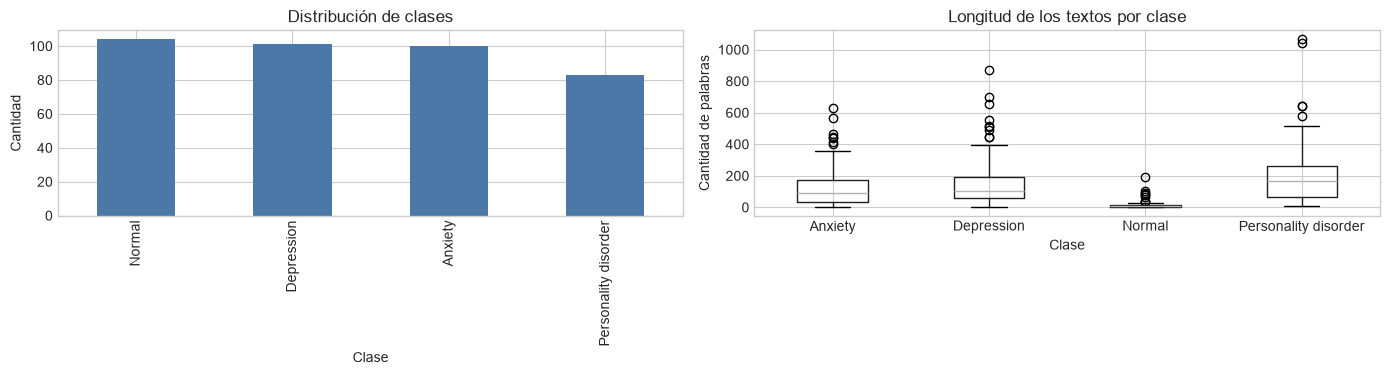

In [30]:
ruta = Path('datasets/balanced_mental_health_dataset_sampled.csv')
if not ruta.exists():
    ruta = Path('../datasets/balanced_mental_health_dataset_sampled.csv')
if not ruta.exists():
    raise FileNotFoundError(f'No se encontró el dataset en: {ruta.resolve()}')

df = pd.read_csv(ruta)
print('Dimensiones originales:', df.shape)
print('Valores faltantes:')
print(df[['statement', 'status']].isna().sum())

df = df.dropna(subset=['statement', 'status']).copy()
df['statement'] = df['statement'].astype(str).str.strip()
df = df[df['statement'] != ''].copy()
df['cantidad_palabras'] = df['statement'].str.split().str.len()

print('Dimensiones luego de limpiar:', df.shape)
print('Cantidad por clase:')
display(df['status'].value_counts().to_frame('cantidad'))
display(df[['cantidad_palabras']].describe())
display(df[['statement', 'status']].head())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df['status'].value_counts().plot.bar(ax=axes[0], color='#4c78a8')
axes[0].set_title('Distribución de clases')
axes[0].set_xlabel('Clase')
axes[0].set_ylabel('Cantidad')
df.boxplot(column='cantidad_palabras', by='status', ax=axes[1])
axes[1].set_title('Longitud de los textos por clase')
axes[1].set_xlabel('Clase')
axes[1].set_ylabel('Cantidad de palabras')
plt.suptitle('')
plt.tight_layout()
plt.show()

## 3. Separación de entrenamiento y test

El test queda reservado. No participa en la búsqueda de hiperparámetros ni en los diagnósticos de selección.

In [31]:
X = df['statement']
y = df['status']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print('Entrenamiento:', len(X_train))
print('Test reservado:', len(X_test))
print('Clases en entrenamiento:')
display(y_train.value_counts().to_frame('cantidad'))
print('Clases en test:')
display(y_test.value_counts().to_frame('cantidad'))

Entrenamiento: 310
Test reservado: 78
Clases en entrenamiento:


,cantidad
status,
Normal,83
Depression,81
Anxiety,80
Personality disorder,66


Clases en test:


,cantidad
status,
Normal,21
Depression,20
Anxiety,20
Personality disorder,17


## 4. Modelos candidatos y búsqueda de hiperparámetros

Se usa `f1_macro` porque todas las clases reciben el mismo peso. La comparación se realiza solamente sobre `X_train` e `y_train`. 

Aca creo que podria ver de agregar a manopla algo para ver si estamos sobreajustando o algo asi, como para justificar mejor la eleccion de hiperparametros

In [32]:
candidatos = {
    'Logistic Regression': (
        Pipeline([
            ('tfidf', TfidfVectorizer()),
            ('classifier', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
        ]),
        {'classifier__C': [0.1, 1, 10]}
    ),
    'Multinomial Naive Bayes': (
        Pipeline([
            ('tfidf', TfidfVectorizer()),
            ('classifier', MultinomialNB())
        ]),
        {'classifier__alpha': [0.1, 1, 10]}
    ),
    'Decision Tree': (
        Pipeline([
            ('tfidf', TfidfVectorizer()),
            ('classifier', DecisionTreeClassifier(random_state=RANDOM_STATE))
        ]),
        {'classifier__max_depth': [5, 10, None]}
    ),
    'Random Forest': (
        Pipeline([
            ('tfidf', TfidfVectorizer()),
            ('classifier', RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1))
        ]),
        {'classifier__n_estimators': [50, 100], 'classifier__max_depth': [10, None]}
    ),
    'SVM lineal': (
        Pipeline([
            ('tfidf', TfidfVectorizer()),
            ('classifier', SVC(kernel='linear'))
        ]),
        {'classifier__C': [0.1, 1, 10]}
    )
}

def seleccionar_modelo(nombre, pipeline, param_grid, X_train, y_train):
    grid = GridSearchCV(
        pipeline, param_grid, cv=CV, scoring=SCORING,
        n_jobs=-1, return_train_score=True
    )
    grid.fit(X_train, y_train)
    indice = grid.best_index_
    return grid, {
        'Modelo': nombre,
        'Macro F1 CV': grid.best_score_,
        'Desvío entre folds': grid.cv_results_['std_test_score'][indice],
        'Mejores parámetros': grid.best_params_
    }

grids = {}
filas = []
for nombre, (pipeline, parametros) in candidatos.items():
    grid, fila = seleccionar_modelo(nombre, pipeline, parametros, X_train, y_train)
    grids[nombre] = grid
    filas.append(fila)

comparacion = (
    pd.DataFrame(filas)
    .sort_values('Macro F1 CV', ascending=False)
    .reset_index(drop=True)
)
display(comparacion)

,Modelo,Macro F1 CV,Desvío entre folds,Mejores parámetros
0,SVM lineal,0.766133,0.052594,{'classifier__C': 1}
1,Logistic Regression,0.761555,0.054499,{'classifier__C': 10}
2,Random Forest,0.620064,0.095202,"{'classifier__max_depth': 10, 'classifier__n_e..."
3,Decision Tree,0.608090,0.084686,{'classifier__max_depth': 5}
4,Multinomial Naive Bayes,0.594666,0.033423,{'classifier__alpha': 0.1}


## 5. Diagnóstico de los modelos usando validación cruzada

Estos gráficos ayudan a entender los modelos, pero no reemplazan la evaluación final. Las predicciones son *out-of-fold*: cada texto se predice con un modelo que no lo vio durante ese fold.

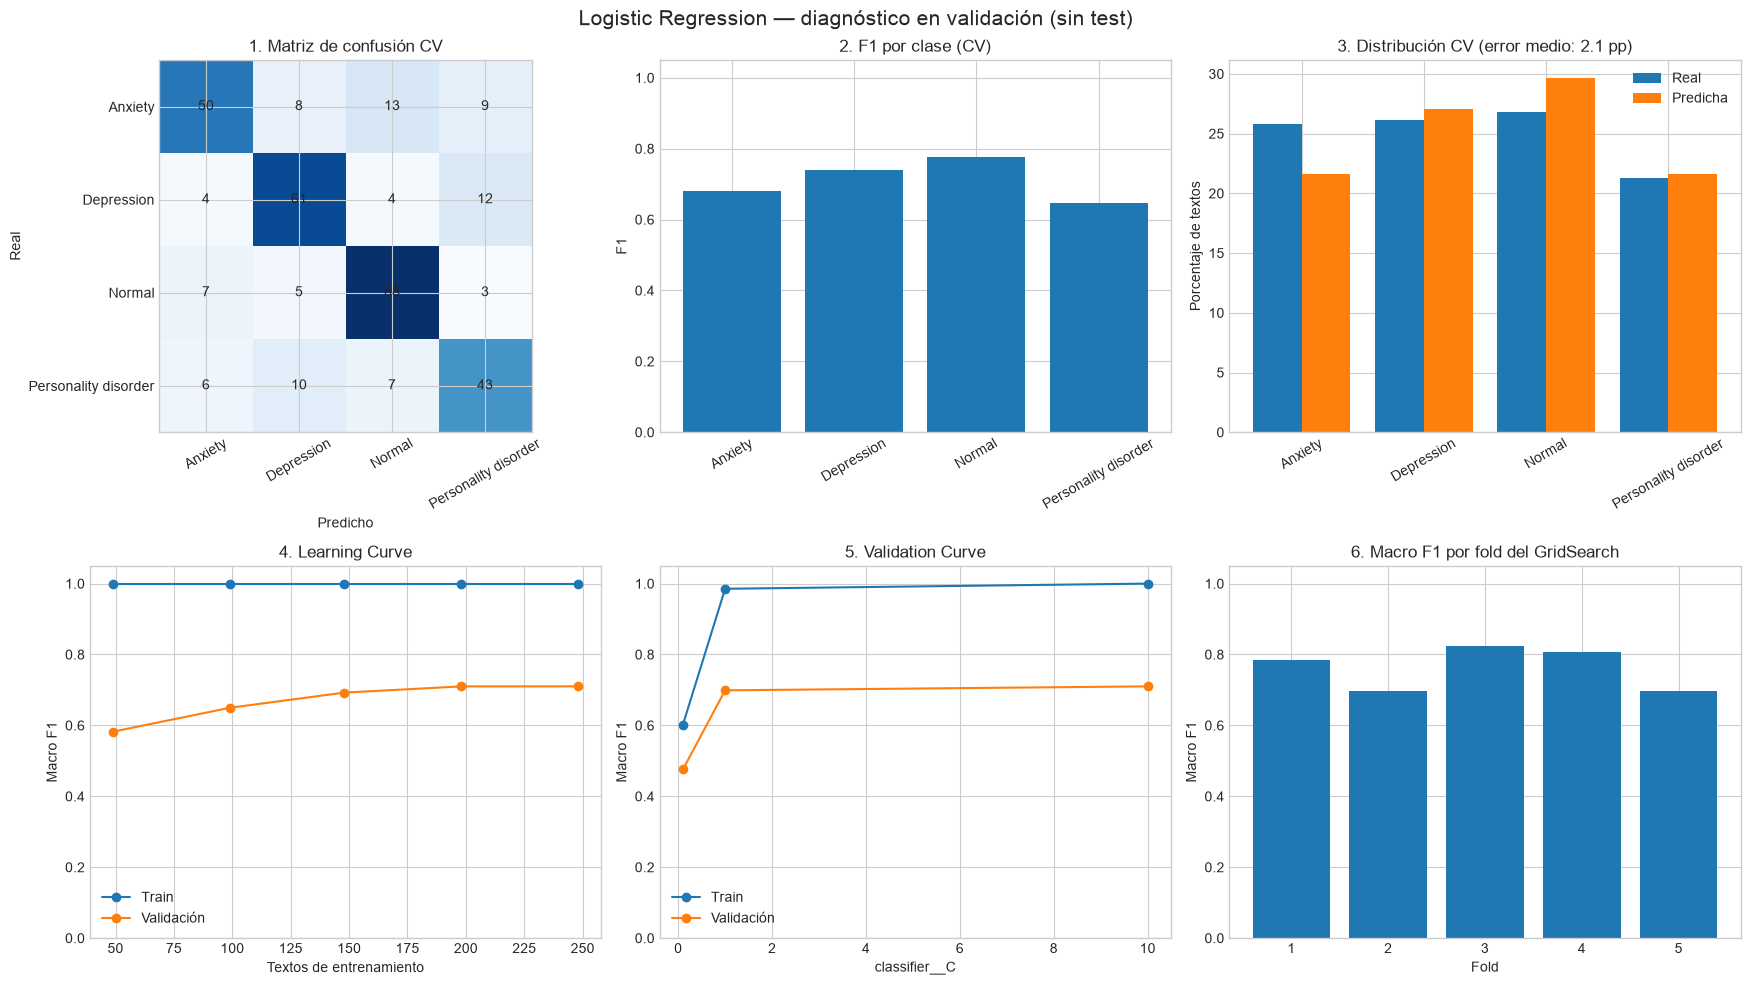

Modelo: Logistic Regression
Mejores hiperparámetros: {'classifier__C': 10}
Macro F1 CV (selección): 0.7616
Diferencia media de distribución: 2.1 pp
Reporte de predicciones de CV (diagnóstico):
                      precision    recall  f1-score   support

             Anxiety       0.75      0.62      0.68        80
          Depression       0.73      0.75      0.74        81
              Normal       0.74      0.82      0.78        83
Personality disorder       0.64      0.65      0.65        66

            accuracy                           0.72       310
           macro avg       0.71      0.71      0.71       310
        weighted avg       0.72      0.72      0.71       310



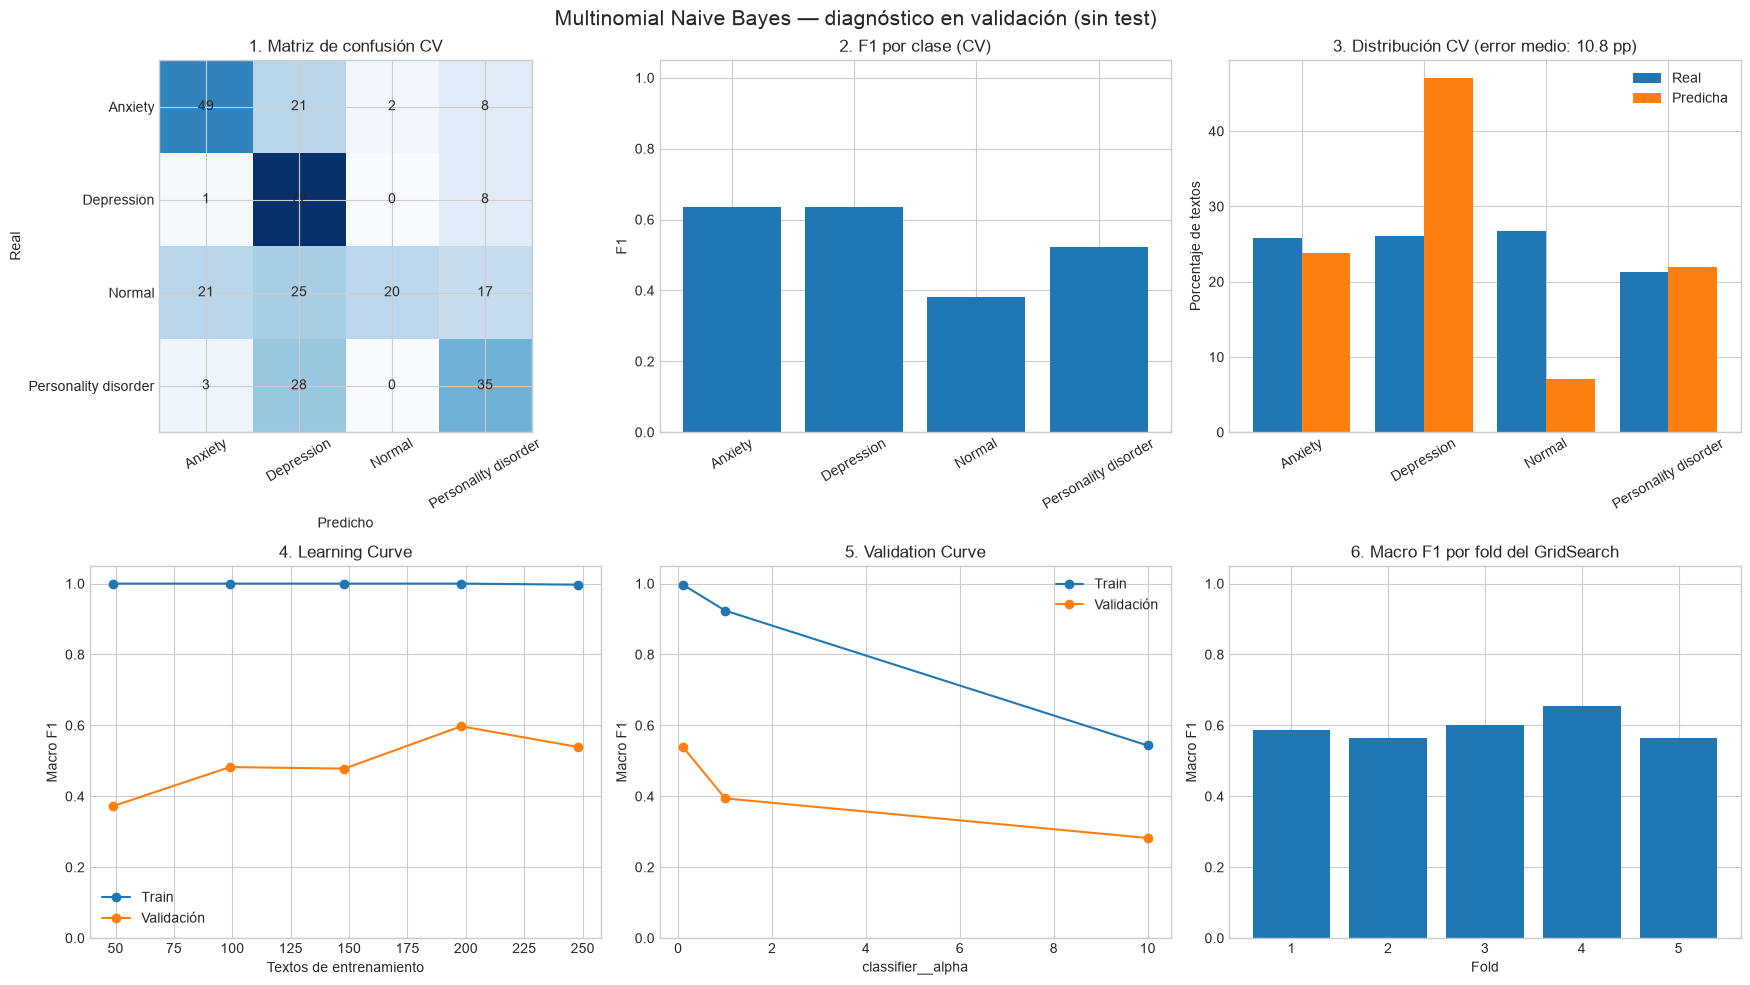

Modelo: Multinomial Naive Bayes
Mejores hiperparámetros: {'classifier__alpha': 0.1}
Macro F1 CV (selección): 0.5947
Diferencia media de distribución: 10.81 pp
Reporte de predicciones de CV (diagnóstico):
                      precision    recall  f1-score   support

             Anxiety       0.66      0.61      0.64        80
          Depression       0.49      0.89      0.63        81
              Normal       0.91      0.24      0.38        83
Personality disorder       0.51      0.53      0.52        66

            accuracy                           0.57       310
           macro avg       0.64      0.57      0.54       310
        weighted avg       0.65      0.57      0.54       310



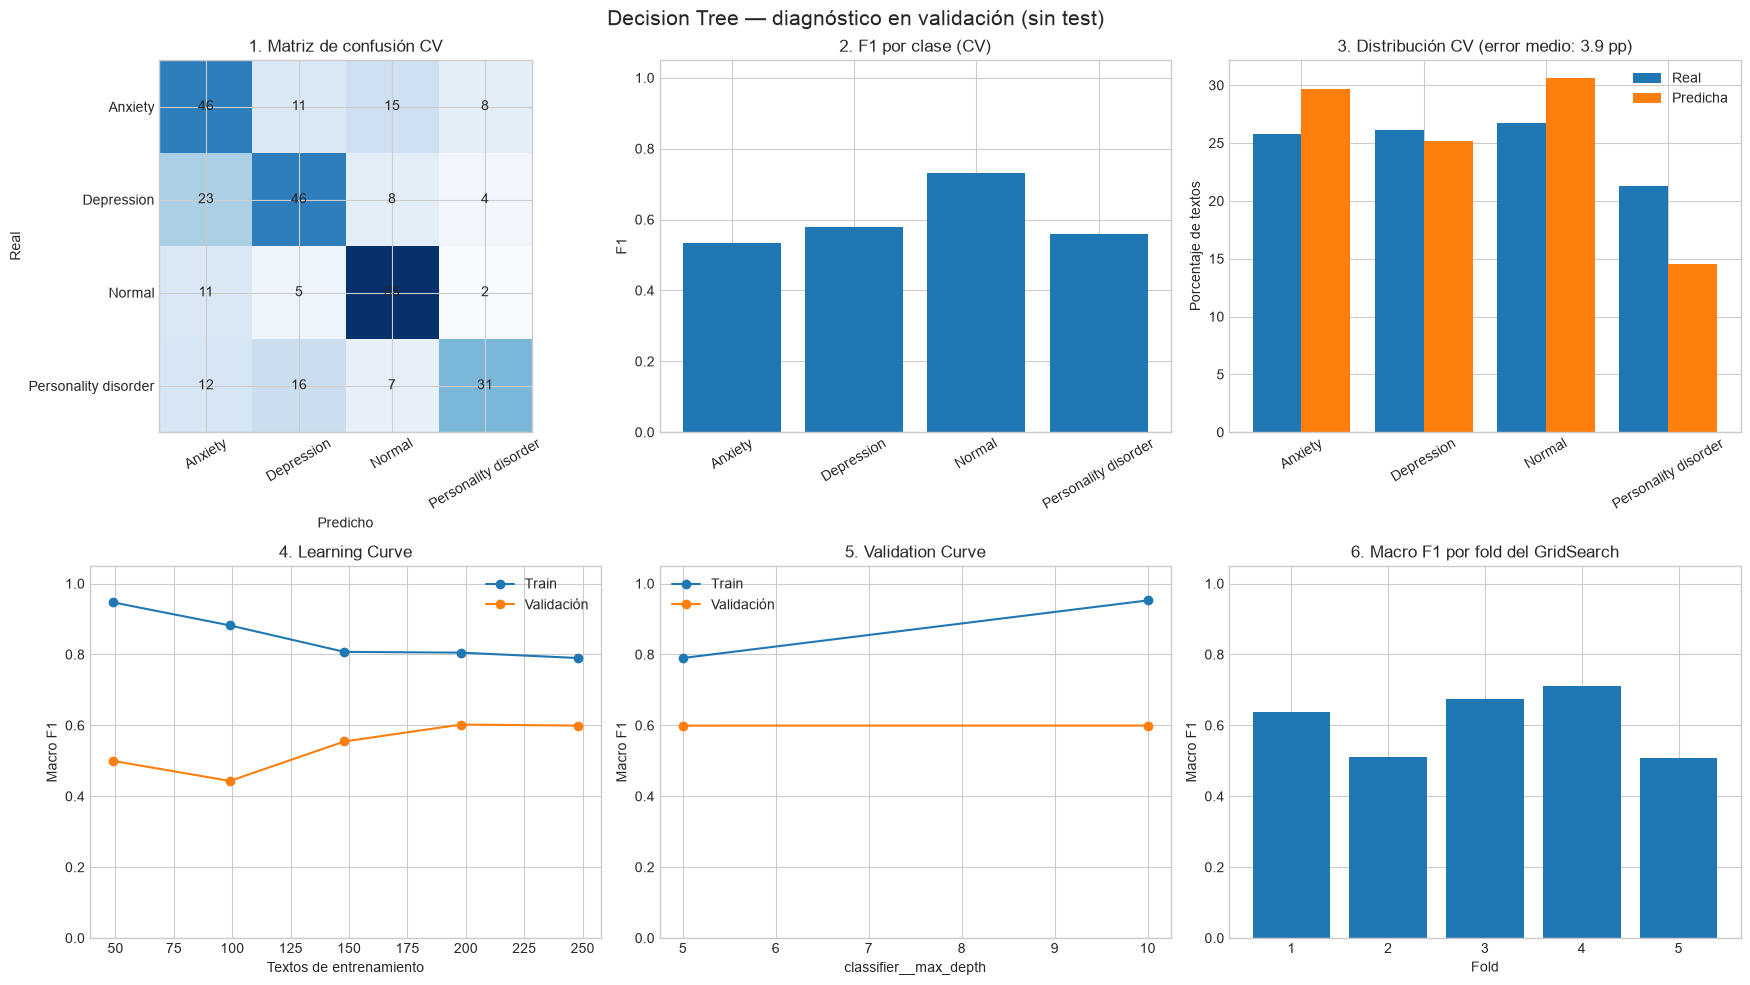

Modelo: Decision Tree
Mejores hiperparámetros: {'classifier__max_depth': 5}
Macro F1 CV (selección): 0.6081
Diferencia media de distribución: 3.87 pp
Reporte de predicciones de CV (diagnóstico):
                      precision    recall  f1-score   support

             Anxiety       0.50      0.57      0.53        80
          Depression       0.59      0.57      0.58        81
              Normal       0.68      0.78      0.73        83
Personality disorder       0.69      0.47      0.56        66

            accuracy                           0.61       310
           macro avg       0.62      0.60      0.60       310
        weighted avg       0.61      0.61      0.60       310



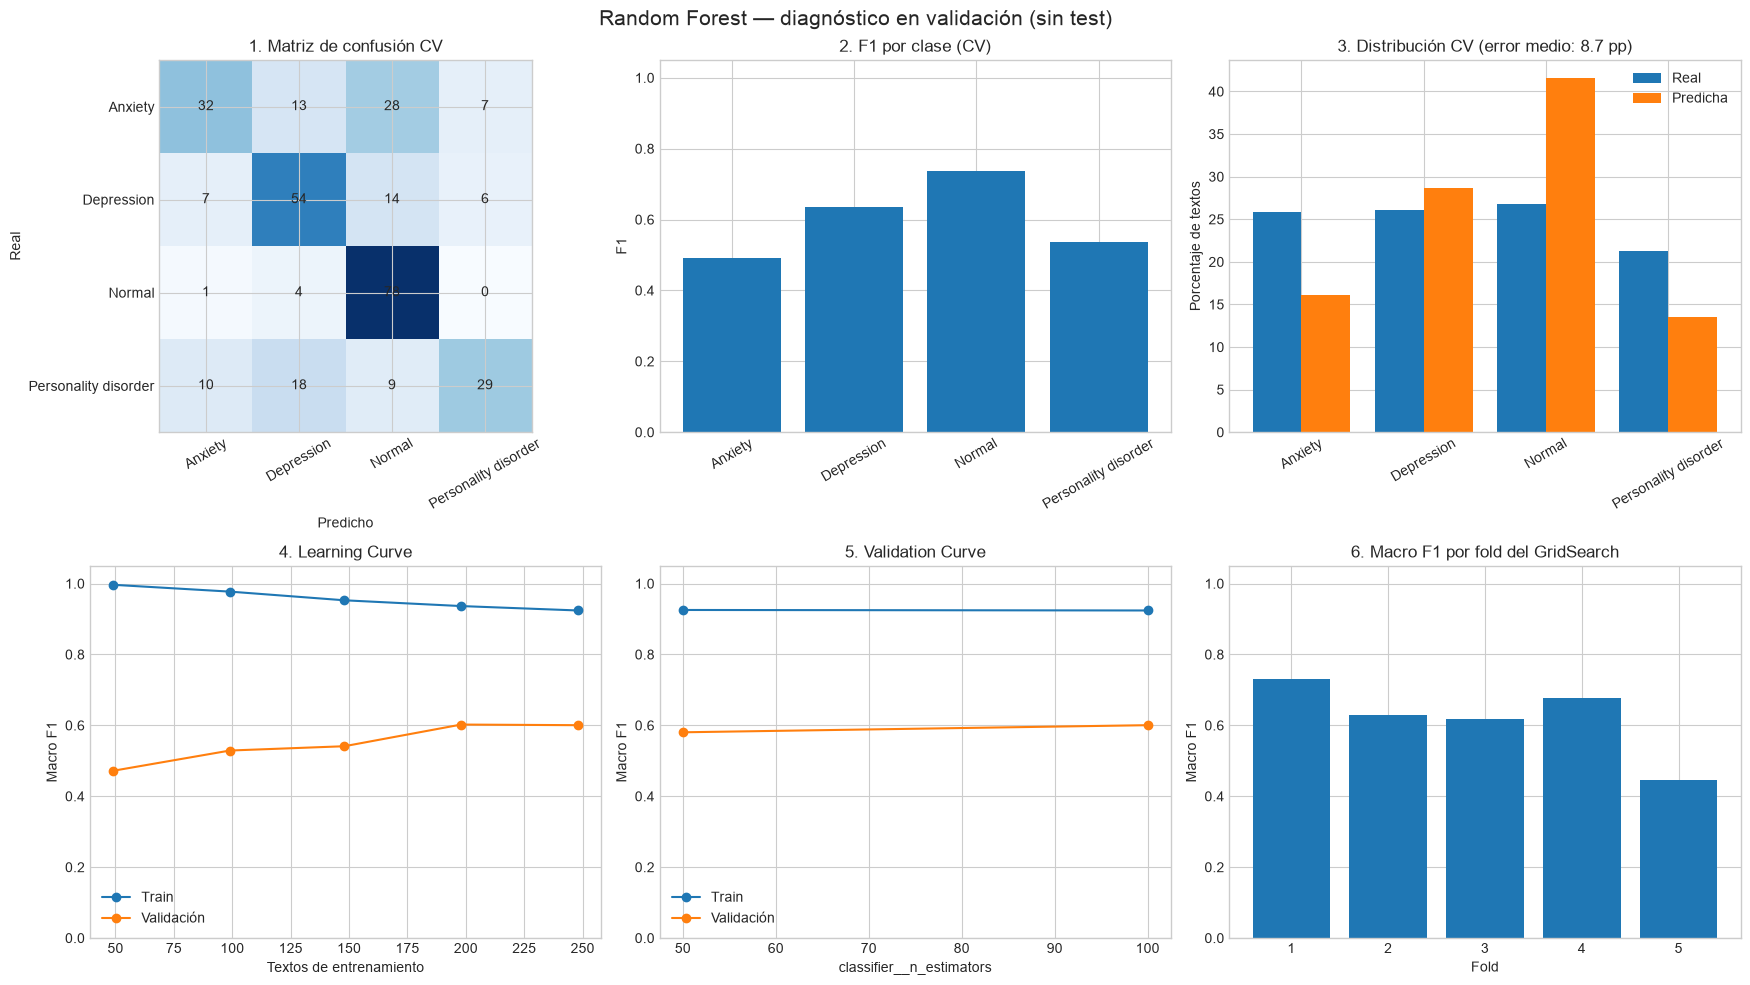

Modelo: Random Forest
Mejores hiperparámetros: {'classifier__max_depth': 10, 'classifier__n_estimators': 100}
Macro F1 CV (selección): 0.6201
Diferencia media de distribución: 8.71 pp
Reporte de predicciones de CV (diagnóstico):
                      precision    recall  f1-score   support

             Anxiety       0.64      0.40      0.49        80
          Depression       0.61      0.67      0.64        81
              Normal       0.60      0.94      0.74        83
Personality disorder       0.69      0.44      0.54        66

            accuracy                           0.62       310
           macro avg       0.64      0.61      0.60       310
        weighted avg       0.63      0.62      0.60       310



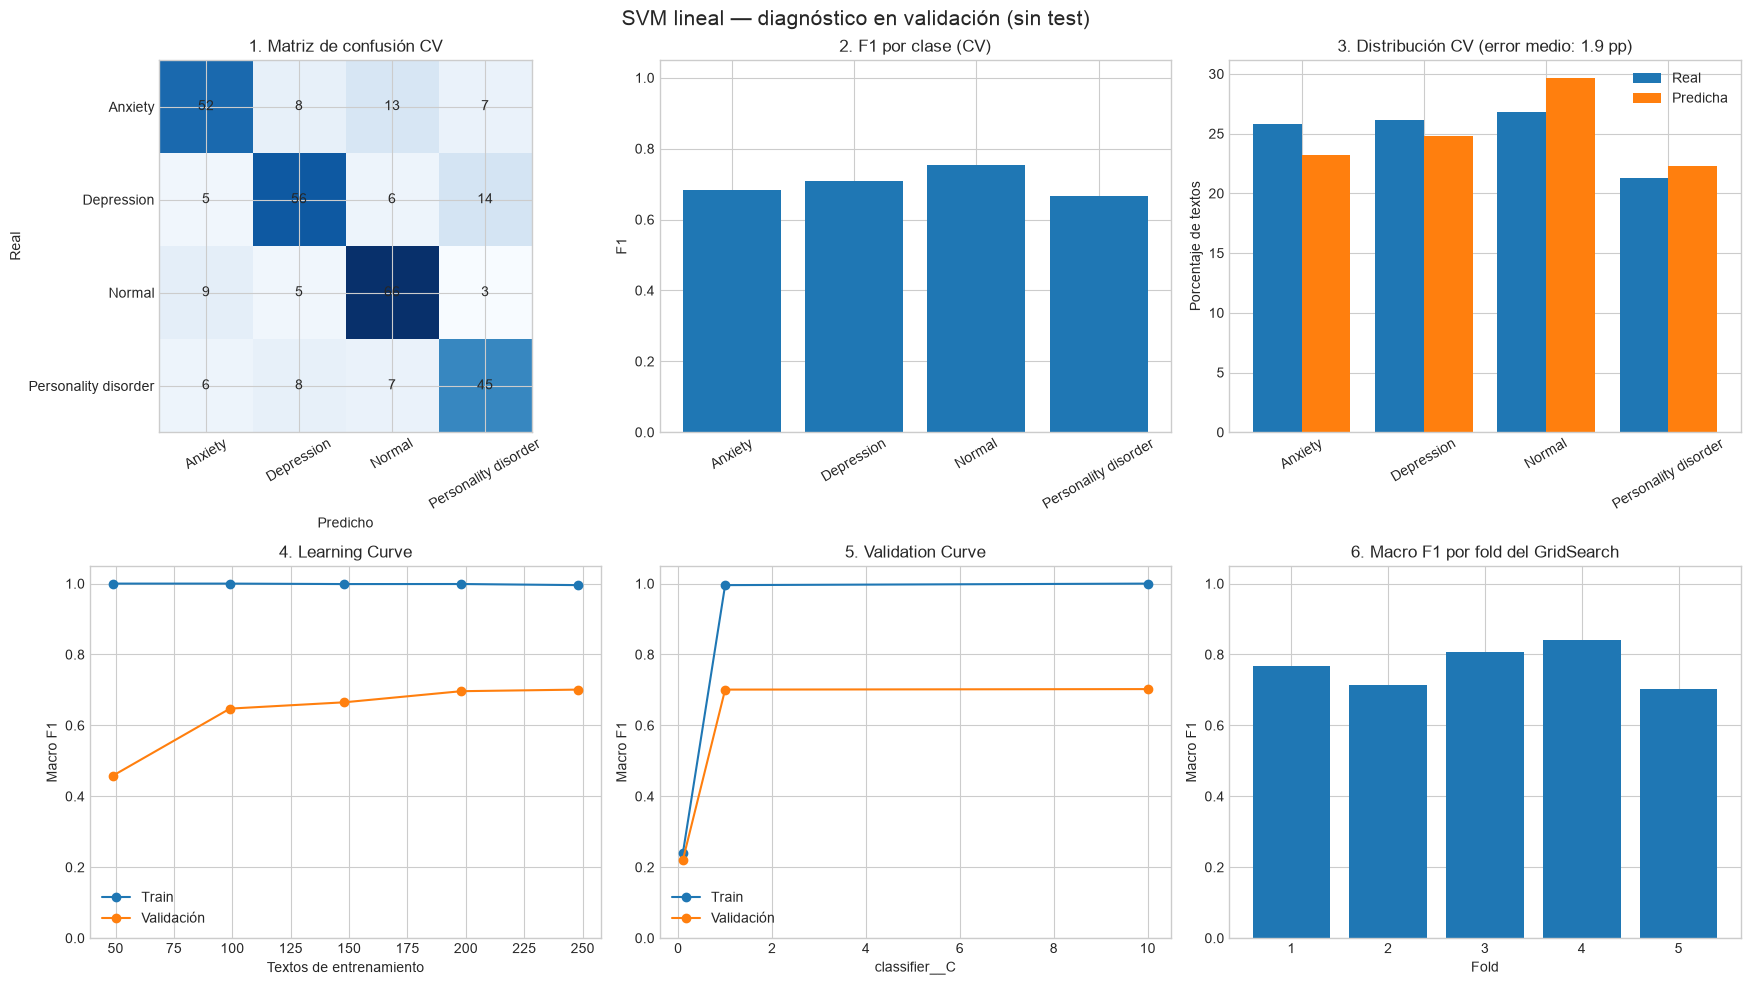

Modelo: SVM lineal
Mejores hiperparámetros: {'classifier__C': 1}
Macro F1 CV (selección): 0.7661
Diferencia media de distribución: 1.94 pp
Reporte de predicciones de CV (diagnóstico):
                      precision    recall  f1-score   support

             Anxiety       0.72      0.65      0.68        80
          Depression       0.73      0.69      0.71        81
              Normal       0.72      0.80      0.75        83
Personality disorder       0.65      0.68      0.67        66

            accuracy                           0.71       310
           macro avg       0.70      0.70      0.70       310
        weighted avg       0.71      0.71      0.71       310



,Modelo,Macro F1 CV (GridSearch),Error medio distribución (pp),Mejores parámetros
4,SVM lineal,0.766133,1.935484,{'classifier__C': 1}
0,Logistic Regression,0.761555,2.096774,{'classifier__C': 10}
3,Random Forest,0.620064,8.709677,"{'classifier__max_depth': 10, 'classifier__n_e..."
2,Decision Tree,0.608090,3.870968,{'classifier__max_depth': 5}
1,Multinomial Naive Bayes,0.594666,10.806452,{'classifier__alpha': 0.1}


In [ ]:
configuraciones = {
    'Logistic Regression': {'parametro': 'classifier__C', 'valores': [0.1, 1, 10], 'log': True},
    'Multinomial Naive Bayes': {'parametro': 'classifier__alpha', 'valores': [0.1, 1, 10], 'log': True},
    'Decision Tree': {'parametro': 'classifier__max_depth', 'valores': [5, 10, None], 'log': False},
    'Random Forest': {'parametro': 'classifier__n_estimators', 'valores': [50, 100], 'log': False},
    'SVM lineal': {'parametro': 'classifier__C', 'valores': [0.1, 1, 10], 'log': True}
}

def evaluar_modelos_cv(grids, configuraciones, X_train, y_train):
    """Diagnósticos de selección; NO recibe X_test ni y_test."""
    resumen = []
    for nombre, grid in grids.items():
        modelo = grid.best_estimator_
        config = configuraciones.get(nombre, {})
        y_pred_cv = cross_val_predict(modelo, X_train, y_train, cv=5, n_jobs=-1)
        clases = sorted(pd.Series(y_train).unique())

        reales = pd.Series(y_train).value_counts(normalize=True).reindex(clases, fill_value=0)
        predichas = pd.Series(y_pred_cv).value_counts(normalize=True).reindex(clases, fill_value=0)
        diferencia = predichas - reales
        error_promedio_pp = diferencia.abs().mean() * 100

        reporte = classification_report(y_train, y_pred_cv, output_dict=True, zero_division=0)
        train_sizes, train_scores, val_scores = learning_curve(
            modelo, X_train, y_train, cv=5, scoring='f1_macro', n_jobs=-1,
            train_sizes=np.linspace(0.2, 1.0, 5)
        )
        fig, axes = plt.subplots(2, 3, figsize=(18, 10))
        fig.suptitle(f'{nombre} — diagnóstico en validación (sin test)', fontsize=15)

        cm = confusion_matrix(y_train, y_pred_cv, labels=clases)
        axes[0, 0].imshow(cm, cmap='Blues')
        for i in range(len(clases)):
            for j in range(len(clases)):
                axes[0, 0].text(j, i, cm[i, j], ha='center', va='center')
        axes[0, 0].set(xticks=range(len(clases)), yticks=range(len(clases)),
                       xticklabels=clases, yticklabels=clases,
                       xlabel='Predicho', ylabel='Real', title='1. Matriz de confusión CV')
        axes[0, 0].tick_params(axis='x', labelrotation=30)

        f1_clases = [reporte[str(c)]['f1-score'] for c in clases]
        axes[0, 1].bar([str(c) for c in clases], f1_clases)
        axes[0, 1].set(title='2. F1 por clase (CV)', ylabel='F1', ylim=(0, 1.05))
        axes[0, 1].tick_params(axis='x', labelrotation=30)

        x = np.arange(len(clases))
        axes[0, 2].bar(x - 0.2, reales.values * 100, width=0.4, label='Real')
        axes[0, 2].bar(x + 0.2, predichas.values * 100, width=0.4, label='Predicha')
        axes[0, 2].set(xticks=x, xticklabels=clases,
                       title=f'3. Distribución CV (error medio: {error_promedio_pp:.1f} pp)',
                       ylabel='Porcentaje de textos')
        axes[0, 2].tick_params(axis='x', labelrotation=30)
        axes[0, 2].legend()

        axes[1, 0].plot(train_sizes, train_scores.mean(axis=1), marker='o', label='Train')
        axes[1, 0].plot(train_sizes, val_scores.mean(axis=1), marker='o', label='Validación')
        axes[1, 0].set(title='4. Learning Curve', xlabel='Textos de entrenamiento', ylabel='Macro F1', ylim=(0,1.05))
        axes[1, 0].legend()

        if 'parametro' in config and 'valores' in config:
            tc, vc = validation_curve(
                modelo, X_train, y_train, param_name=config['parametro'],
                param_range=config['valores'], cv=5, scoring='f1_macro', n_jobs=-1
            )
            axes[1, 1].plot(config['valores'], tc.mean(axis=1), marker='o', label='Train')
            axes[1, 1].plot(config['valores'], vc.mean(axis=1), marker='o', label='Validación')
            if config.get('escala_log', False):
                axes[1, 1].set_xscale('log')
            axes[1, 1].set(title='5. Validation Curve', xlabel=config['parametro'], ylabel='Macro F1', ylim=(0,1.05))
            axes[1, 1].legend()
        else:
            axes[1, 1].set_title('5. Sin hiperparámetro para curva')
            axes[1, 1].axis('off')

        indice = grid.best_index_
        valores_fold = [grid.cv_results_[f'split{i}_test_score'][indice] for i in range(grid.n_splits_)]
        axes[1, 2].bar(range(1, len(valores_fold) + 1), valores_fold)
        axes[1, 2].set(title='6. Macro F1 por fold del GridSearch', xlabel='Fold', ylabel='Macro F1', ylim=(0,1.05))

        plt.tight_layout()
        plt.show()
        print('Modelo:', nombre)
        print('Mejores hiperparámetros:', grid.best_params_)
        print('Macro F1 CV (selección):', round(grid.best_score_, 4))
        print('Diferencia media de distribución:', round(error_promedio_pp, 2), 'pp')
        print('Reporte de predicciones de CV (diagnóstico):')
        print(classification_report(y_train, y_pred_cv, zero_division=0))
        resumen.append({
            'Modelo': nombre,
            'Macro F1 CV (GridSearch)': grid.best_score_,
            'Error medio distribución (pp)': error_promedio_pp,
            'Mejores parámetros': grid.best_params_
        })
    return pd.DataFrame(resumen).sort_values('Macro F1 CV (GridSearch)', ascending=False)

tabla_diagnostico = evaluar_modelos_cv(grids, configuraciones, X_train, y_train)
display(tabla_diagnostico)

## 6. Elección automática antes de mirar el test

Para que puedas ejecutar el notebook completo sin completar celdas manualmente, se elige el primer modelo de la tabla de validación. Esta decisión usa únicamente `Macro F1 CV`.

In [34]:
nombre_elegido = comparacion.iloc[0]['Modelo']
modelo_elegido = grids[nombre_elegido].best_estimator_
print('Modelo elegido antes de mirar el test:', nombre_elegido)
print('Hiperparámetros:', grids[nombre_elegido].best_params_)
print('Macro F1 de validación:', round(grids[nombre_elegido].best_score_, 4))

Modelo elegido antes de mirar el test: SVM lineal
Hiperparámetros: {'classifier__C': 1}
Macro F1 de validación: 0.7661


## 7. Evaluación final sobre el test reservado

Esta es la primera sección que utiliza `X_test` e `y_test`. El test no se usa para cambiar la elección del modelo.

Modelo final: SVM lineal
Accuracy en test: 0.7821
Reporte de clasificación en test:
                      precision    recall  f1-score   support

             Anxiety       0.78      0.90      0.84        20
          Depression       0.81      0.65      0.72        20
              Normal       0.78      0.86      0.82        21
Personality disorder       0.75      0.71      0.73        17

            accuracy                           0.78        78
           macro avg       0.78      0.78      0.78        78
        weighted avg       0.78      0.78      0.78        78



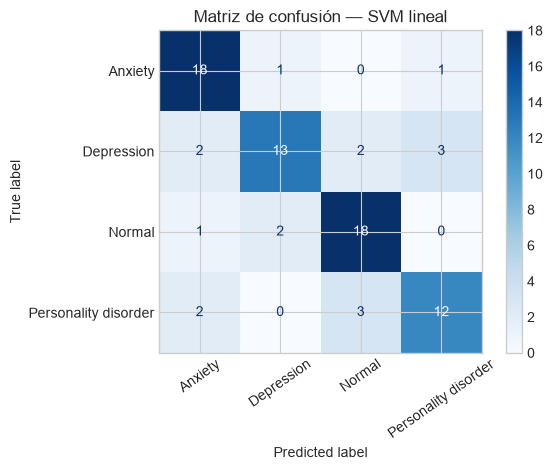

In [35]:
y_pred_test = modelo_elegido.predict(X_test)

print(f'Modelo final: {nombre_elegido}')
print(f'Accuracy en test: {accuracy_score(y_test, y_pred_test):.4f}')
print('Reporte de clasificación en test:')
print(classification_report(y_test, y_pred_test, zero_division=0))

clases = list(modelo_elegido.classes_)
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_test, labels=clases, cmap='Blues', xticks_rotation=35
)
plt.title(f'Matriz de confusión — {nombre_elegido}')
plt.tight_layout()
plt.show()

## 8. Cómo interpretar el resultado

- `Macro F1 CV`: criterio usado para elegir el modelo. Promedia el F1 de las cuatro clases.
- `Desvío entre folds`: indica cuánto varió el resultado entre particiones de validación.
- `Learning Curve`: permite observar si agregar datos mejora la validación y si hay una brecha grande entre train y validación.
- `Validation Curve`: muestra qué ocurre al cambiar el hiperparámetro principal.
- Matriz de confusión: muestra qué clases se confunden.
- Resultado final: informa cómo funciona el modelo elegido sobre datos que no participaron en la selección.

La puntuación del test sirve para informar el desempeño final, no para elegir otro modelo después de verla.